In [1]:
import os
import re
import glob
import zipfile
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

nltk.download('stopwords')

url = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
zip_path = "sentiment_dataset.zip"

if not os.path.exists(zip_path):
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("sentiment_data")

files = [f for f in glob.glob("sentiment_data/**/*_labelled.txt", recursive=True)]
dfs = []
for f in files:
    source_name = os.path.basename(f).split('_')[0]
    temp_df = pd.read_csv(f, sep='\t', header=None, names=['text', 'label'], quoting=3)
    temp_df['source'] = source_name
    dfs.append(temp_df)

df = pd.concat(dfs, ignore_index=True)
print(f"Dataset shape: {df.shape}")
print(df['label'].value_counts())
df.head()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


Dataset shape: (3000, 3)
label
0    1500
1    1500
Name: count, dtype: int64


,text,label,source
0,So there is no way for me to plug it in here i...,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more...,0,amazon
4,The mic is great.,1,amazon


In [2]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_text'] = df['text'].apply(clean_text)

comparison = df[['text', 'clean_text', 'label']].head(10)
display(comparison)

,text,clean_text,label
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",good case excellent value,1
2,Great for the jawbone.,great for the jawbone,1
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...,0
4,The mic is great.,the mic is great,1
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...,0
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...,0
7,If you are Razr owner...you must have this!,if you are razr owneryou must have this,1
8,"Needless to say, I wasted my money.",needless to say i wasted my money,0
9,What a waste of money and time!.,what a waste of money and time,0


--- POSITIVE EXAMPLES (Label = 1) ---
• Good case, Excellent value.
• Great for the jawbone.
• The mic is great.
• If you are Razr owner...you must have this!
• And the sound quality is great.

--- NEGATIVE EXAMPLES (Label = 0) ---
• So there is no way for me to plug it in here in the US unless I go by a converter.
• Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!
• I have to jiggle the plug to get it to line up right to get decent volume.
• If you have several dozen or several hundred contacts, then imagine the fun of sending each of them one by one.
• Needless to say, I wasted my money.


C:\Users\User\AppData\Local\Temp\ipykernel_19832\1959138624.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[c for _, c in pos_words], y=[w for w, _ in pos_words], ax=axes[0], palette='Greens_r')
C:\Users\User\AppData\Local\Temp\ipykernel_19832\1959138624.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[c for _, c in neg_words], y=[w for w, _ in neg_words], ax=axes[1], palette='Reds_r')


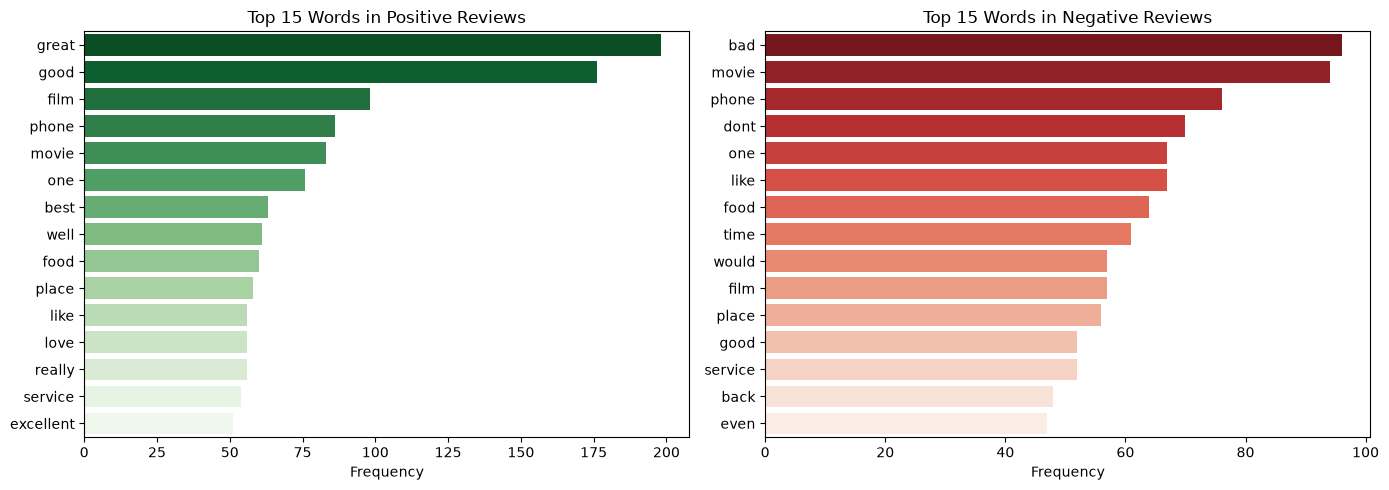

In [3]:
print("--- POSITIVE EXAMPLES (Label = 1) ---")
for s in df[df['label'] == 1]['text'].head(5):
    print("•", s)

print("\n--- NEGATIVE EXAMPLES (Label = 0) ---")
for s in df[df['label'] == 0]['text'].head(5):
    print("•", s)

stop_words = set(stopwords.words('english'))

def get_top_words(series, n=15):
    words = [w for text in series for w in text.split() if w not in stop_words and len(w) > 2]
    return Counter(words).most_common(n)

pos_words = get_top_words(df[df['label'] == 1]['clean_text'])
neg_words = get_top_words(df[df['label'] == 0]['clean_text'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=[c for _, c in pos_words], y=[w for w, _ in pos_words], ax=axes[0], palette='Greens_r')
axes[0].set_title('Top 15 Words in Positive Reviews')
axes[0].set_xlabel('Frequency')

sns.barplot(x=[c for _, c in neg_words], y=[w for w, _ in neg_words], ax=axes[1], palette='Reds_r')
axes[1].set_title('Top 15 Words in Negative Reviews')
axes[1].set_xlabel('Frequency')

plt.tight_layout()
plt.savefig('word_frequency_comparison.png', dpi=150)
plt.show()

In [4]:
X = df['clean_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

vectorizer = CountVectorizer(stop_words='english', max_features=5000)
X_train_bow = vectorizer.fit_transform(X_train)
X_test_bow = vectorizer.transform(X_test)

print(f"Training BOW matrix shape: {X_train_bow.shape}")
print(f"Testing BOW matrix shape:  {X_test_bow.shape}")

Training BOW matrix shape: (2400, 4389)
Testing BOW matrix shape:  (600, 4389)


=== Logistic Regression ===
              precision    recall  f1-score   support

    Negative       0.81      0.81      0.81       300
    Positive       0.81      0.82      0.81       300

    accuracy                           0.81       600
   macro avg       0.81      0.81      0.81       600
weighted avg       0.81      0.81      0.81       600

=== Linear SVM ===
              precision    recall  f1-score   support

    Negative       0.81      0.75      0.78       300
    Positive       0.77      0.83      0.80       300

    accuracy                           0.79       600
   macro avg       0.79      0.79      0.79       600
weighted avg       0.79      0.79      0.79       600



,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.811667,0.808581,0.816667,0.812604
Linear SVM,0.788333,0.767802,0.826667,0.796148


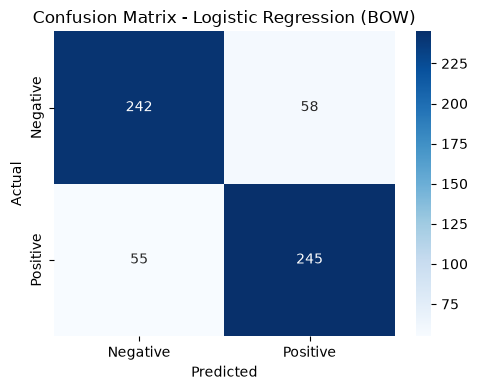

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Linear SVM": LinearSVC(random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train_bow, y_train)
    y_pred = model.predict(X_test_bow)
    
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred)
    }
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

results_df = pd.DataFrame(results).T
display(results_df)

best_model = models["Logistic Regression"]
cm = confusion_matrix(y_test, best_model.predict(X_test_bow))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title('Confusion Matrix - Logistic Regression (BOW)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

In [6]:
new_sentences = [
    "This product exceeded my expectations, absolutely brilliant quality!",
    "Terrible service and the food arrived completely cold.",
    "The movie was okay, nothing special but not bad either.",
    "Worst purchase I have ever made. Complete waste of money."
]

cleaned_new = [clean_text(s) for s in new_sentences]
new_bow = vectorizer.transform(cleaned_new)
predictions = best_model.predict(new_bow)

for sentence, pred in zip(new_sentences, predictions):
    sentiment = "Positive" if pred == 1 else "Negative"
    print(f"[{sentiment}] -> {sentence}")

[Positive] -> This product exceeded my expectations, absolutely brilliant quality!
[Negative] -> Terrible service and the food arrived completely cold.
[Negative] -> The movie was okay, nothing special but not bad either.
[Negative] -> Worst purchase I have ever made. Complete waste of money.
